In [1]:
# 1️⃣ Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
from google.colab import files
uploaded = files.upload()

Saving preprocessed_heart_data.csv to preprocessed_heart_data.csv


In [4]:
# 2️⃣ Load dataset
df = pd.read_csv('/content/preprocessed_heart_data.csv')

print("✅ Dataset Loaded Successfully")
print("Shape:", df.shape)
print(df.head())

✅ Dataset Loaded Successfully
Shape: (836, 8)
          0         1         2         3         4         5         6  \
0  0.347050 -0.679673 -0.499973  0.713224  2.071518 -0.107874  0.726331   
1  0.646453 -0.966573  1.620895  1.107131 -0.606688  0.206072 -0.889755   
2  1.868226 -1.178756  1.778446 -0.957983 -0.548572  1.087457  0.181305   
3  0.321740  0.391937  0.943680 -0.783433  1.459503 -0.187247  0.844320   
4  0.163327 -0.883790 -1.569414 -1.014261 -1.305411  0.021747 -1.111000   

   target  
0       0  
1       0  
2       0  
3       0  
4       1  


In [5]:
# 3️⃣ Split features and target
target_col = 'target' if 'target' in df.columns else df.columns[-1]
X = df.drop(target_col, axis=1)
y = df[target_col]

In [6]:
# 4️⃣ Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nData Split Done:")
print("Train size:", X_train.shape)
print("Test size:", X_test.shape)


Data Split Done:
Train size: (668, 7)
Test size: (168, 7)


In [7]:
# 🌳 VARIETY 1: Gini criterion, max_depth=10, min_samples_split=2
# ==============================================
dt1 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    min_samples_split=2,
    random_state=42
)
dt1.fit(X_train, y_train)
y_pred1 = dt1.predict(X_test)

acc1 = accuracy_score(y_test, y_pred1)
cv1 = cross_val_score(dt1, X_train, y_train, cv=5).mean()

print("\n🌳 Variety 1 Results (Gini, depth=10, split=2):")
print("Accuracy:", round(acc1, 4))
print("Cross-Validation Accuracy:", round(cv1, 4))
print(classification_report(y_test, y_pred1))


🌳 Variety 1 Results (Gini, depth=10, split=2):
Accuracy: 0.9762
Cross-Validation Accuracy: 0.964
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        78
           1       1.00      0.96      0.98        90

    accuracy                           0.98       168
   macro avg       0.98      0.98      0.98       168
weighted avg       0.98      0.98      0.98       168



In [8]:
# 🌳 VARIETY 2: Entropy criterion, max_depth=15, min_samples_split=5
# ==============================================
dt2 = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=15,
    min_samples_split=5,
    random_state=42
)
dt2.fit(X_train, y_train)
y_pred2 = dt2.predict(X_test)

acc2 = accuracy_score(y_test, y_pred2)
cv2 = cross_val_score(dt2, X_train, y_train, cv=5).mean()

print("\n🌳 Variety 2 Results (Entropy, depth=15, split=5):")
print("Accuracy:", round(acc2, 4))
print("Cross-Validation Accuracy:", round(cv2, 4))
print(classification_report(y_test, y_pred2))


🌳 Variety 2 Results (Entropy, depth=15, split=5):
Accuracy: 0.9821
Cross-Validation Accuracy: 0.9535
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        78
           1       1.00      0.97      0.98        90

    accuracy                           0.98       168
   macro avg       0.98      0.98      0.98       168
weighted avg       0.98      0.98      0.98       168



In [9]:
# 🌳 VARIETY 3: Gini criterion, max_depth=20, with pruning
# ==============================================
path = DecisionTreeClassifier(
    criterion='gini',
    max_depth=20,
    random_state=42
).cost_complexity_pruning_path(X_train, y_train)

ccp_alpha = path.ccp_alphas[len(path.ccp_alphas)//2]  # middle alpha
print("\n🔧 Selected ccp_alpha for pruning:", ccp_alpha)

dt3 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=20,
    ccp_alpha=ccp_alpha,
    random_state=42
)
dt3.fit(X_train, y_train)
y_pred3 = dt3.predict(X_test)

acc3 = accuracy_score(y_test, y_pred3)
cv3 = cross_val_score(dt3, X_train, y_train, cv=5).mean()

print("\n🌳 Variety 3 Results (Gini, depth=20, pruned):")
print("Accuracy:", round(acc3, 4))
print("Cross-Validation Accuracy:", round(cv3, 4))
print(classification_report(y_test, y_pred3))


🔧 Selected ccp_alpha for pruning: 0.005626120794811864

🌳 Variety 3 Results (Gini, depth=20, pruned):
Accuracy: 0.8571
Cross-Validation Accuracy: 0.8773
              precision    recall  f1-score   support

           0       0.89      0.79      0.84        78
           1       0.84      0.91      0.87        90

    accuracy                           0.86       168
   macro avg       0.86      0.85      0.86       168
weighted avg       0.86      0.86      0.86       168



In [10]:
# 🧠 VARIETY 4 (BONUS): Hyperparameter Tuning via Grid Search
# ==============================================
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': [None, 'sqrt', 'log2']
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("\n🔍 Best Hyperparameters Found:")
print(grid.best_params_)

best_dt = grid.best_estimator_
y_pred4 = best_dt.predict(X_test)

acc4 = accuracy_score(y_test, y_pred4)
cv4 = cross_val_score(best_dt, X_train, y_train, cv=5).mean()

print("\n🌳 Variety 4 (Tuned Model) Results:")
print("Accuracy:", round(acc4, 4))
print("Cross-Validation Accuracy:", round(cv4, 4))
print(classification_report(y_test, y_pred4))


🔍 Best Hyperparameters Found:
{'criterion': 'gini', 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

🌳 Variety 4 (Tuned Model) Results:
Accuracy: 0.9762
Cross-Validation Accuracy: 0.9761
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        78
           1       1.00      0.96      0.98        90

    accuracy                           0.98       168
   macro avg       0.98      0.98      0.98       168
weighted avg       0.98      0.98      0.98       168



In [11]:
# 📊 Compare All Varieties
# ==============================================
results = pd.DataFrame({
    'Model Variety': ['Variety 1', 'Variety 2', 'Variety 3', 'Variety 4 (Tuned)'],
    'Criterion': ['Gini', 'Entropy', 'Gini (Pruned)', str(grid.best_params_['criterion'])],
    'Max Depth': [10, 15, 20, grid.best_params_['max_depth']],
    'Min Samples Split': [2, 5, 'Default', grid.best_params_['min_samples_split']],
    'Cross-Val Accuracy': [cv1, cv2, cv3, cv4],
    'Test Accuracy': [acc1, acc2, acc3, acc4]
})

print("\n📈 Final Model Comparison Table:")
print(results)


📈 Final Model Comparison Table:
       Model Variety      Criterion  Max Depth Min Samples Split  \
0          Variety 1           Gini         10                 2   
1          Variety 2        Entropy         15                 5   
2          Variety 3  Gini (Pruned)         20           Default   
3  Variety 4 (Tuned)           gini         15                 2   

   Cross-Val Accuracy  Test Accuracy  
0            0.964000       0.976190  
1            0.953529       0.982143  
2            0.877275       0.857143  
3            0.976052       0.976190  


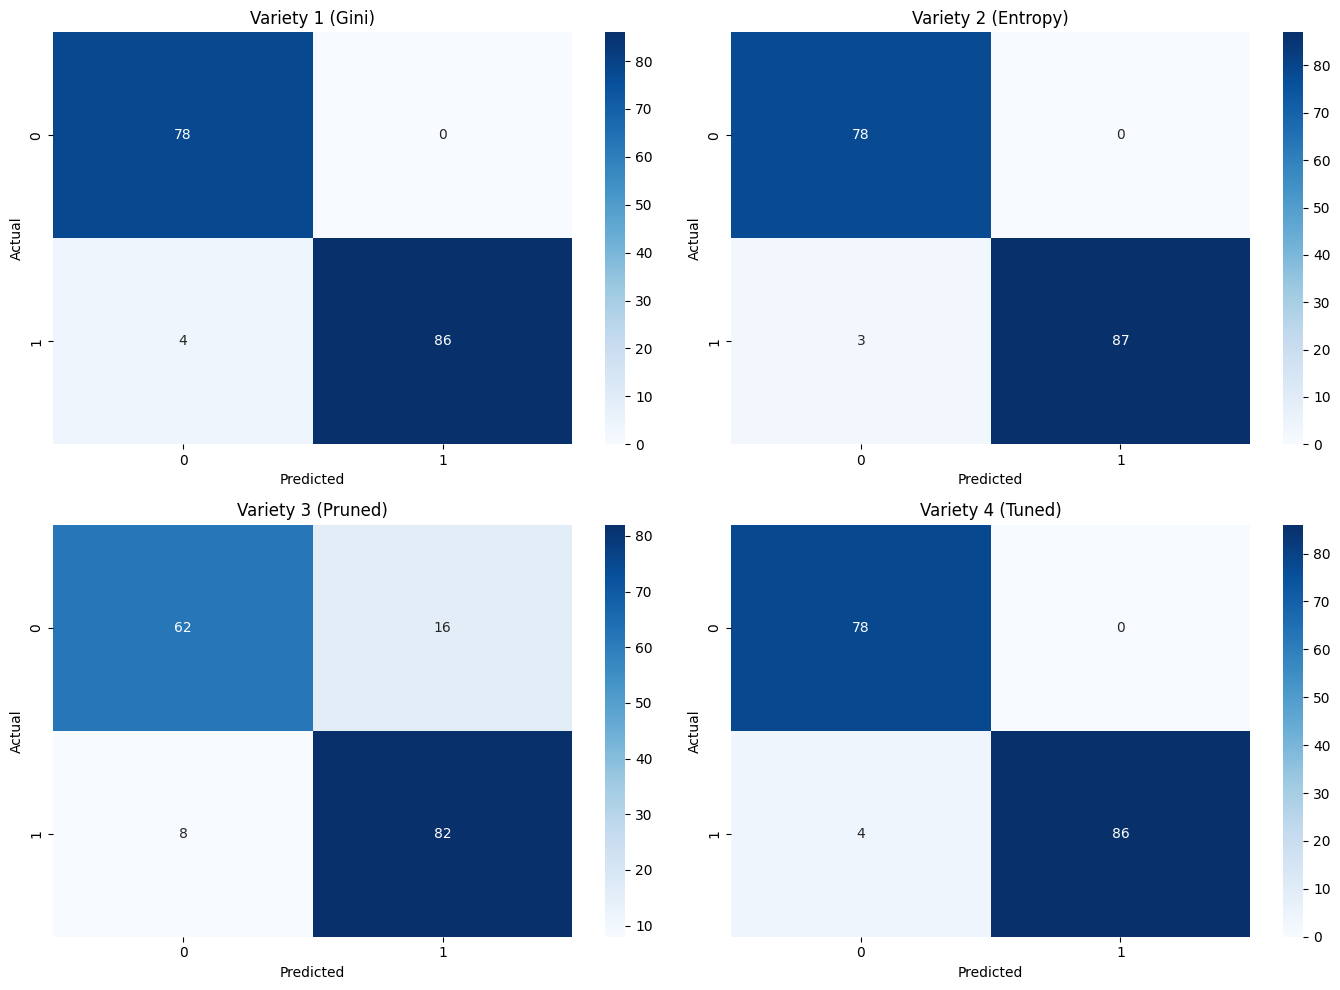

In [12]:
# 🔥 Confusion Matrices
# ==============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
titles = ['Variety 1 (Gini)', 'Variety 2 (Entropy)', 'Variety 3 (Pruned)', 'Variety 4 (Tuned)']
preds = [y_pred1, y_pred2, y_pred3, y_pred4]

for i, ax in enumerate(axes.flatten()):
    cm = confusion_matrix(y_test, preds[i])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(titles[i])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

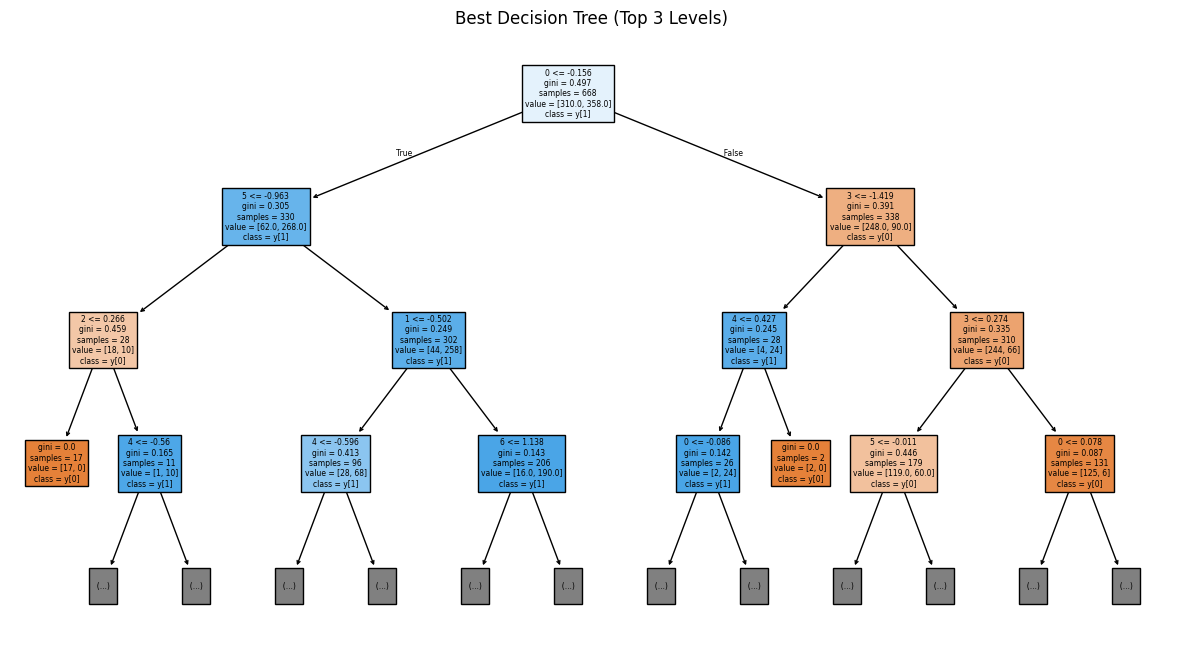

In [13]:
# 🌲 Visualize the Best Tree
# ==============================================
plt.figure(figsize=(15,8))
plot_tree(best_dt, filled=True, feature_names=X.columns, class_names=True, max_depth=3)
plt.title("Best Decision Tree (Top 3 Levels)")
plt.show()

In [14]:
# 🏆 Best Model
# ==============================================
print("\n✅ All Models Completed Successfully!")
best_model = results.loc[results['Test Accuracy'].idxmax()]
print("\n🏆 Best Performing Model:\n", best_model)


✅ All Models Completed Successfully!

🏆 Best Performing Model:
 Model Variety         Variety 2
Criterion               Entropy
Max Depth                    15
Min Samples Split             5
Cross-Val Accuracy     0.953529
Test Accuracy          0.982143
Name: 1, dtype: object
